In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler         #Estandarizar variables numéricas para el análisis o modelado
from imblearn.over_sampling import RandomOverSampler 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

#### Data set : MAGIC Gamma Telescope
Url: https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope
Obj: Distingir dos tipos de partículas a partir de características registradas por un telescopio de rayos gamma.

In [2]:
cols = ["fLength", "fWidth", "fSize", "fConc", "fConc1",
        "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist", "class"]
df = pd.read_csv("magic04.data", names=cols)
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [3]:
df["class"].unique()

<ArrowStringArray>
['g', 'h']
Length: 2, dtype: str

#### Convertir el tipo de dato "class" de str en int

In [4]:
df["class"] = (df["class"] == "g").astype(int)  #Convierte los valores booleanos en números enteros
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,1
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,1
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,1
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,1
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,1


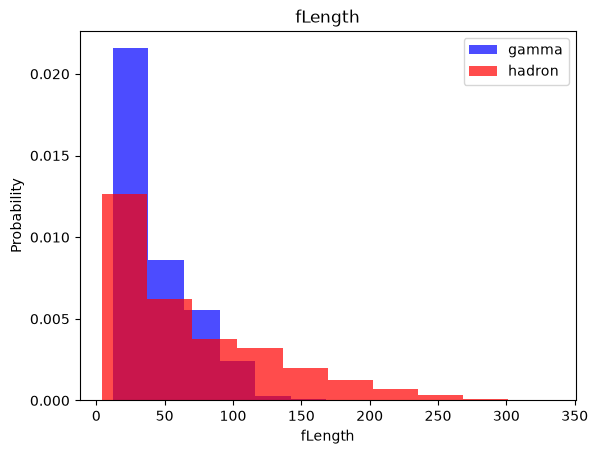

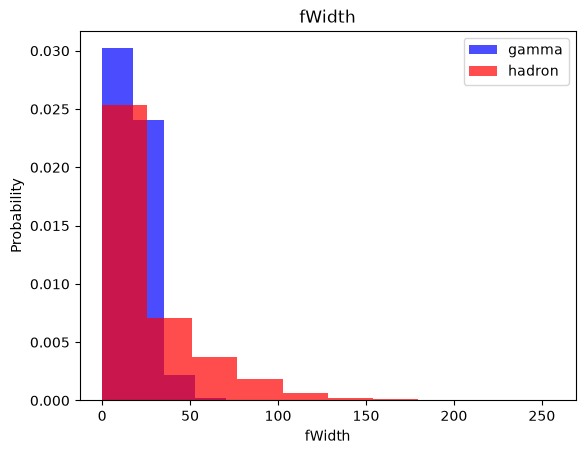

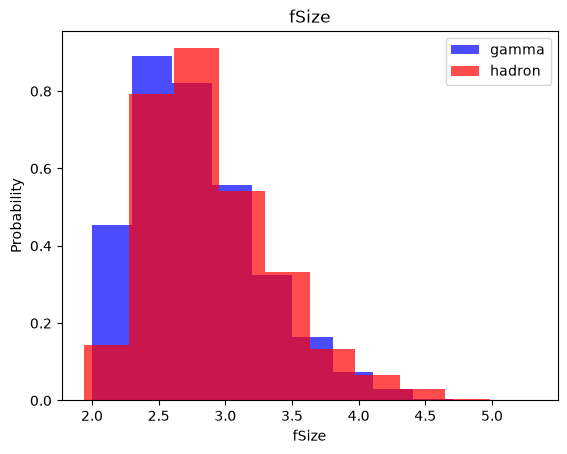

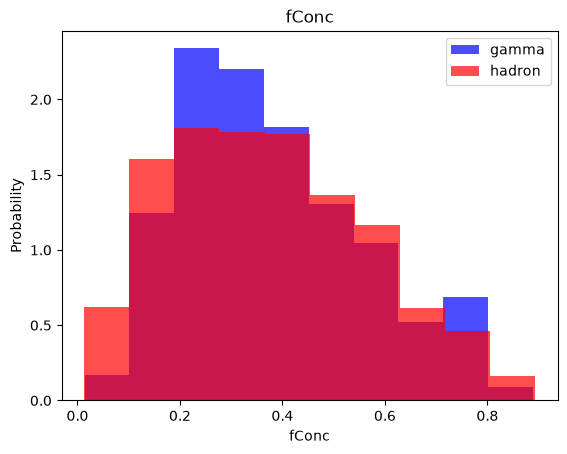

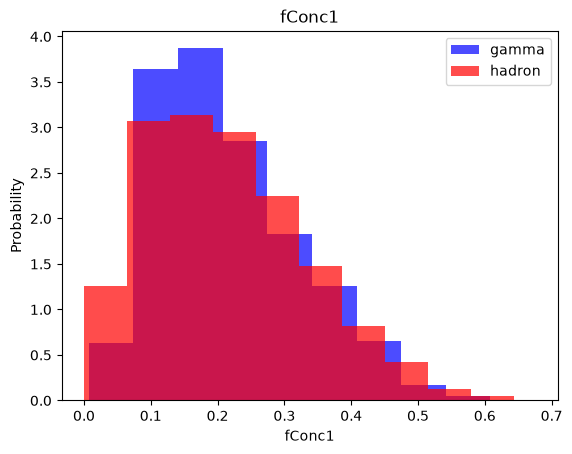

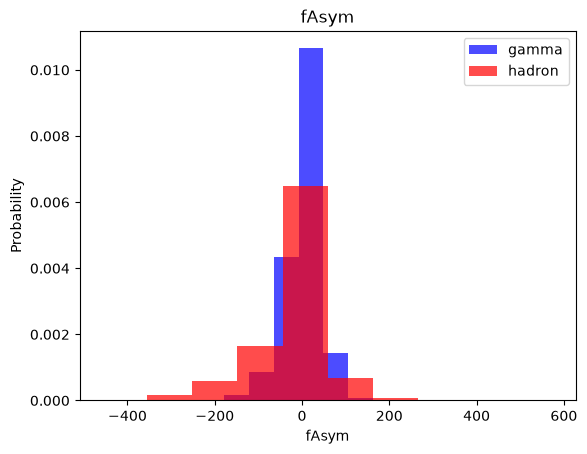

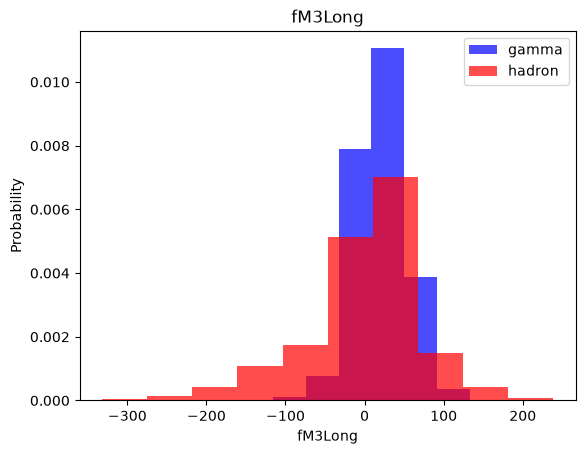

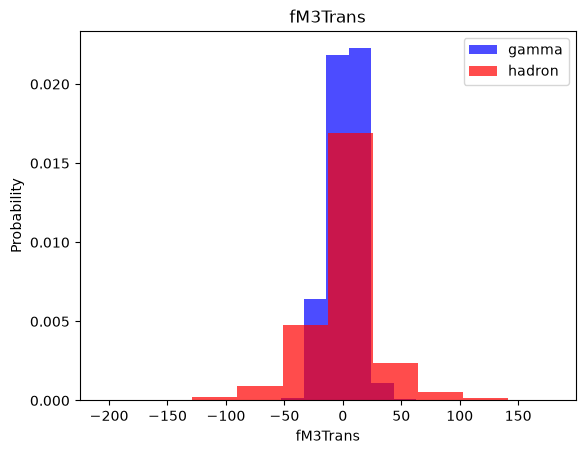

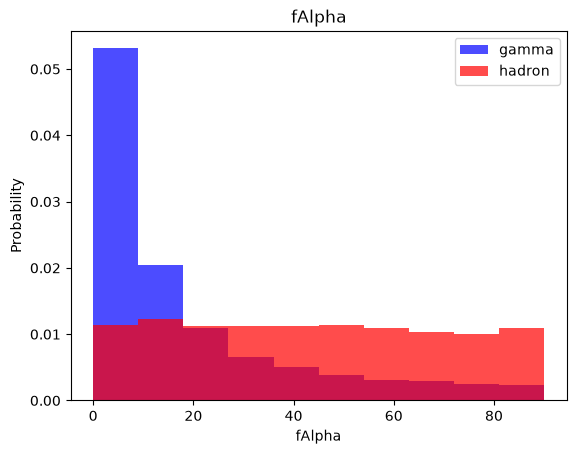

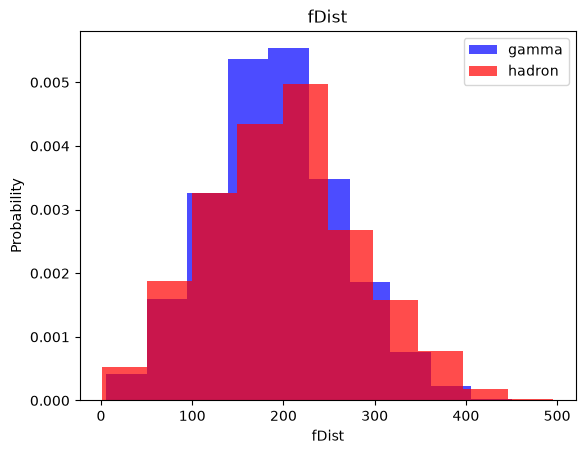

In [5]:
for label in cols[:-1]:
    plt.hist(df[df["class"]== 1][label], 
             color='blue', label='gamma', 
             alpha=0.7, density=True)
    plt.hist(df[df["class"]== 0][label], 
             color='red', label='hadron', 
             alpha=0.7, density=True)
    plt.title(label)
    plt.ylabel("Probability")
    plt.xlabel(label)
    plt.legend()
    plt.show()

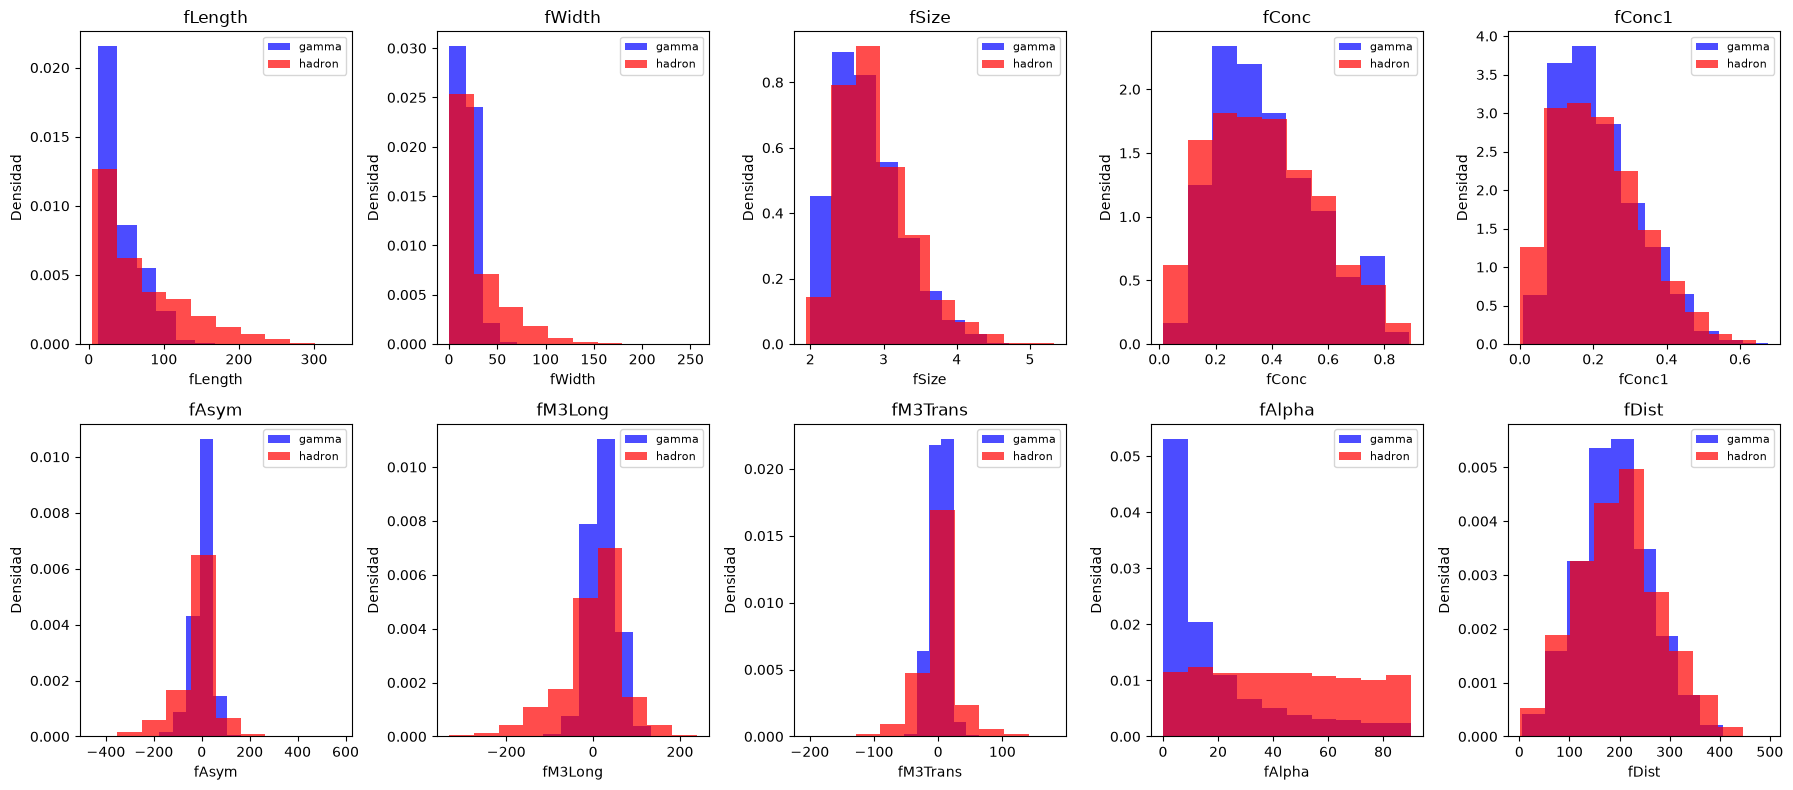

In [6]:
# Crear una figura con 2 filas y 5 columnas
features = cols[:-1]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

# Convertir la matriz de ejes en una lista
axes = axes.flatten()

for ax, label in zip(axes, features):

    # Histograma de gamma
    ax.hist(
        df[df["class"] == 1][label],
        color="blue",
        label="gamma",
        alpha=0.7,
        density=True
    )

    # Histograma de hadron
    ax.hist(
        df[df["class"] == 0][label],
        color="red",
        label="hadron",
        alpha=0.7,
        density=True
    )

    # Configurar cada gráfico
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Densidad")
    ax.legend(fontsize=8)

# Ajustar los espacios entre gráficos
plt.tight_layout()
plt.show()

#### Train, Validation, Test - Datasets

In [7]:
# Mezclar las filas
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Calcular los índices
n = len(df_shuffled)
i_train = int(0.6 * n)
i_valid = int(0.8 * n)

# Dividir los datos conservando las columnas
train = df_shuffled.iloc[:i_train]              #desde la primera fila hasta antes de i_train
valid = df_shuffled.iloc[i_train:i_valid]      #desde i_train hasta antes de i_valid
test = df_shuffled.iloc[i_valid:]             #desde i_valid hasta el final

np.split() convierte el Dataframe de pandas en un array de Numpy - por ello no lo usaremos.

sample(frac=1) -- selecciona el 100% de las filas para mezclarlas en un orden aleatorio.
random_state=42 -- hace que la mezcla pueda ser reproducible.
reset_index(drop=True) -- reorganiza los índices para que vuelvan a ser consecutivos y elimina el índice anterior.
i_train -- define el punto donde terminará el conjunto de entrenamiento. 
El índice marca un límite acumulado, primero se toma el 60% de los datos para entrenamiento y, después, las filas hasta alcanzar el 80% total. Estas filas intermedias representan el 20% de validación. 
iloc -- permite seleccionar filas y columnas de un Dataframe utilizando sus posiciones numéricas, y conserva los nombres de sus columnas. 

In [8]:
def scale_dataset(dataframe, scaler=None, fit_scaler=False, oversample=False):
    x = dataframe[dataframe.columns[:-1]].values
    y = dataframe[dataframe.columns[-1]].values
    
    if scaler is None: 
        scaler = StandardScaler()

    if fit_scaler:
        x = scaler.fit_transform(x)    #Solo se estandarizan las características
    else:
        x = scaler.transform(x)
    
    if oversample:
        ros = RandomOverSampler(random_state=42)
        x, y = ros.fit_resample(x, y)    #Sobremuestreo de las características y sus etiquetas al mismo tiempo

    data = np.hstack((x, np.reshape(y, (-1, 1))))  #Transforma un vector y lo une horizantalmente

    return data, x, y, scaler

In [9]:
train_data, x_train, y_train, scaler = scale_dataset(train, fit_scaler=True, oversample=True)
valid_data, x_valid, y_valid, _ = scale_dataset(valid, scaler=scaler, fit_scaler=False, oversample=False)
test_data, x_test, y_test, _ = scale_dataset(test, scaler=scaler, fit_scaler=False, oversample=False)

El objetivo de incorporar 'oversample' es corregir el desequilibrio entre las clases gamma y hadron, así el modelo tendrá suficientes ejemplos de ambas clases durante el entrenamiento. 
RandomOverSampler -- Repite ejemplos existentes para equilibrar las cantidades que recibe el modelo durante el entrenamiento.
fit -- Calcula la media y la desviación estándar de cada característica.
transform -- Utiliza esos valores para transformar las observaciones. 
No se aplica 'Oversample' a la validación ni la prueba, porque esos conjuntos deben permitir comprobar cómo se comporta el modelo con datos que conservan una distribución representativa de las obs originales, equilibrarlos artificialmente podría distorcionar las métricas de evalución. 

El escalador debe ser el mismo para el conjunto de validación y prueba, para mantener un proceso coherente y evitar la fuga de información. 

El símbolo '_' significa que se recibe el cuarto resultado, pero no se necesita guardarlo porque ya se tiene el escalador en la variable "scaler".

In [10]:
print(len(y_train))
print(sum(y_train==0))
print(sum(y_train==1))

14818
7409
7409


In [11]:
#Regresión logística
log_model= LogisticRegression(max_iter=2000, random_state=42)  #Se define el modelo
log_model.fit(x_train, y_train)
#Random Forest
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1) 
rf_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [12]:
print("Iteraciones utilizadas:", log_model.n_iter_)

Iteraciones utilizadas: [18]


In [13]:
models = {"Regresión Logística": log_model, "Random Forest": rf_model}

#Predicciones
y_pre_log = log_model.predict(x_valid)        #Devuelve una clase para cada obs
prob_log = log_model.predict_proba(x_valid)
y_prob_log = prob_log[:,1]   #Consultar la probabilidad estimada de gamma

y_pre_rf = rf_model.predict(x_valid)
prob_rf = rf_model.predict_proba(x_valid)  #Probabilidad estimada para cada clase 0 y 1
y_prob_rf = prob_rf[:,1]


In [14]:
results = []

for name, model in models.items():    #toma los modelos guardados en el diccionario
    y_pred = model.predict(x_valid)   #etiqueta que predice el modelo para las obs de validación

    gamma_index = list(model.classes_).index(1)     
    y_prob = model.predict_proba(x_valid)[:, gamma_index]

    results.append({
        "Modelo":name,
        "Balanced accuracy": balanced_accuracy_score(y_valid, y_pred),
        "Precision gamma": precision_score(y_valid, y_pred, pos_label=1, zero_division=0),
        "Recall gamma": recall_score(y_valid, y_pred, pos_label=1, zero_division=0),
        "F1 gamma": f1_score(y_valid, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, y_prob),
    })

    print(f"\nModelo: {name}")
    print("Matriz de confusión:")
    print(confusion_matrix(y_valid, y_pred, labels=[0,1]))

#print(results)
#print(pd.DataFrame(results).columns)  #Visualizar nombres de columnas que contiene la tabla

results_df = pd.DataFrame(results).set_index("Modelo")
display(results_df.round(3))


Modelo: Regresión Logística
Matriz de confusión:
[[1007  347]
 [ 440 2010]]

Modelo: Random Forest
Matriz de confusión:
[[1073  281]
 [ 164 2286]]


,Balanced accuracy,Precision gamma,Recall gamma,F1 gamma,ROC-AUC
Modelo,,,,,
Regresión Logística,0.782,0.853,0.820,0.836,0.847
Random Forest,0.863,0.891,0.933,0.911,0.938


In [17]:
# Ejem: elegir el modelo con mayor balanced accuracy en validación
best_name = results_df["Balanced accuracy"].idxmax()
best_model = models[best_name]

print("Modelo seleccionado:", best_name)

# Evaluarlo con los datos de prueba
y_test_pred = best_model.predict(x_test)

gamma_index = list(best_model.classes_).index(1)
y_test_prob = best_model.predict_proba(x_test)[:, gamma_index]

metricas = { 
    "Balanced accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Precision gamma": precision_score(y_test, y_test_pred, pos_label=1, zero_division=0),
    "Recall gamma": recall_score(y_test, y_test_pred, pos_label=1, zero_division=0),
    "F1 gamma": f1_score(y_test, y_test_pred, pos_label=1, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob)
}

tabla_metricas = pd.DataFrame(
    [metricas],
    index=[best_name]
)

tabla_metricas.index.name = "Modelo"

print("RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA")
display(tabla_metricas.round(3))

matriz = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

tabla_confusion = pd.DataFrame(
    matriz,
    index=["Real: Hadron (0)", "Real: Gamma (1)"],
    columns=["Predicho: Hadron (0)", "Predicho: Gamma (1)"]
)

print("MATRIZ DE CONFUSIÓN")
display(tabla_confusion)

Modelo seleccionado: Random Forest
RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA


,Balanced accuracy,Precision gamma,Recall gamma,F1 gamma,ROC-AUC
Modelo,,,,,
Random Forest,0.851,0.888,0.917,0.902,0.933


MATRIZ DE CONFUSIÓN


,Predicho: Hadron (0),Predicho: Gamma (1)
Real: Hadron (0),1044,287
Real: Gamma (1),206,2267
